In [5]:

!pip -q install datasets

from datasets import load_dataset

dataset = load_dataset("okhater/SICE")

print(dataset)


Resolving data files:   0%|          | 0/1280 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/223 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1280 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/223 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1280
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 223
    })
})


In [7]:
for split in dataset.keys():
    print(split, ":", len(dataset[split]), "records")

print("Features:", dataset["train"].features)

train : 1280 records
test : 223 records
Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['sample_1', 'sample_10', 'sample_100', 'sample_101', 'sample_102', 'sample_103', 'sample_105', 'sample_106', 'sample_107', 'sample_108', 'sample_109', 'sample_11', 'sample_111', 'sample_112', 'sample_113', 'sample_114', 'sample_115', 'sample_116', 'sample_117', 'sample_118', 'sample_119', 'sample_120', 'sample_121', 'sample_122', 'sample_123', 'sample_124', 'sample_125', 'sample_126', 'sample_127', 'sample_128', 'sample_129', 'sample_130', 'sample_131', 'sample_132', 'sample_134', 'sample_135', 'sample_136', 'sample_137', 'sample_138', 'sample_139', 'sample_140', 'sample_141', 'sample_142', 'sample_143', 'sample_144', 'sample_145', 'sample_146', 'sample_147', 'sample_148', 'sample_149', 'sample_150', 'sample_151', 'sample_152', 'sample_153', 'sample_154', 'sample_155', 'sample_156', 'sample_157', 'sample_158', 'sample_159', 'sample_16', 'sample_160', 'sample_161', 'samp

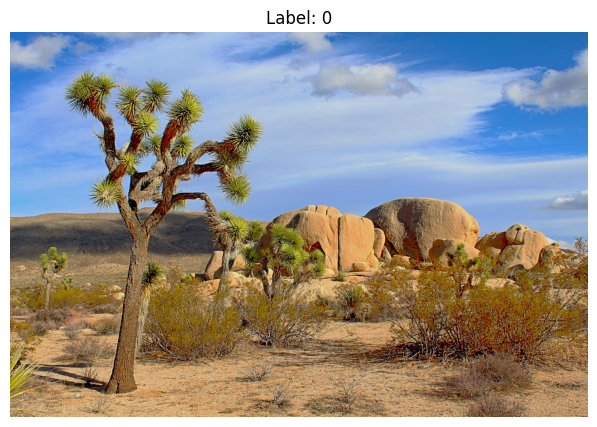

In [8]:
import matplotlib.pyplot as plt

sample = dataset["train"][0]

plt.figure(figsize=(8, 5))
plt.imshow(sample["image"])
plt.title(f'Label: {sample["label"]}')
plt.axis("off")
plt.show()

In [9]:
print("Image size:", sample["image"].size)
print("Image mode:", sample["image"].mode)
print("Label:", sample["label"])

Image size: (5184, 3456)
Image mode: RGB
Label: 0


In [1]:

!pip -q install opencv-python-headless matplotlib numpy

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Setup completed successfully!")
print("OpenCV version:", cv2.__version__)


Setup completed successfully!
OpenCV version: 5.0.0


In [10]:
from collections import Counter

for split in dataset.keys():
    labels = dataset[split]["label"]
    print(f"\n{split}:")
    print("Number of images:", len(labels))
    print("Images per label (first 10):")
    print(Counter(labels).most_common(10))


train:
Number of images: 1280
Images per label (first 10):
[(34, 9), (36, 9), (37, 9), (38, 9), (183, 9), (139, 7), (143, 7), (145, 7), (10, 6), (15, 6)]

test:
Number of images: 223
Images per label (first 10):
[(264, 9), (254, 6), (268, 6), (269, 6), (275, 6), (4, 5), (5, 5), (156, 5), (189, 5), (245, 5)]



Label ID: 34
Label name: sample_134
Number of images: 9


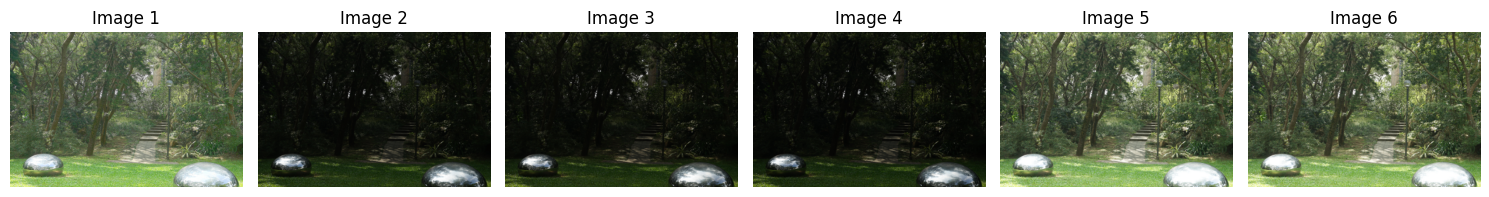


Label ID: 36
Label name: sample_136
Number of images: 9


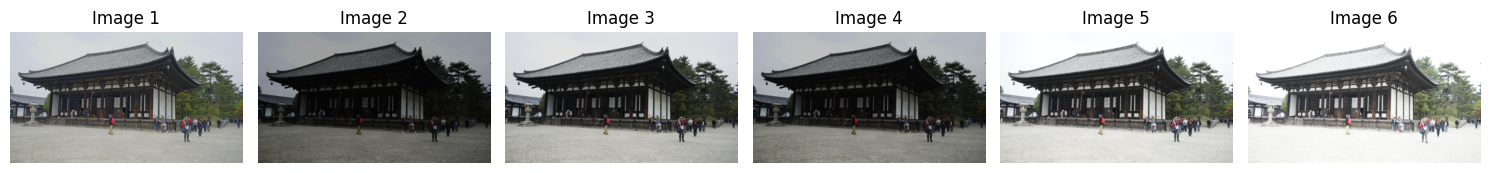


Label ID: 37
Label name: sample_137
Number of images: 9


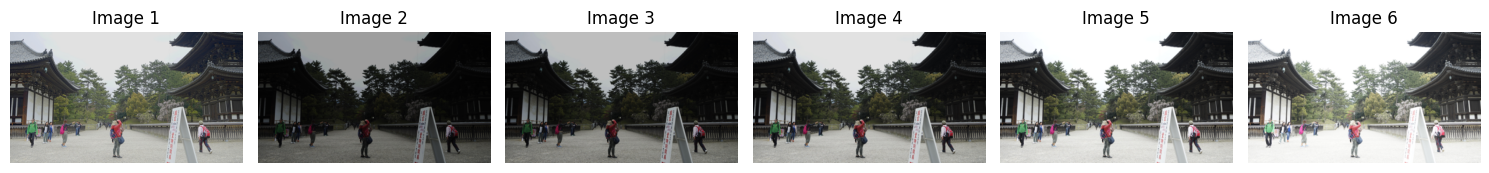

In [11]:
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

# በtrain dataset ውስጥ ብዙ ምስሎች ያሉትን label እንመርጥ
labels = dataset["train"]["label"]
counts = Counter(labels)

# ብዙ ምስሎች ያሉትን 3 label አሳይ
for label, count in counts.most_common(3):
    label_name = dataset["train"].features["label"].int2str(label)
    print(f"\nLabel ID: {label}")
    print(f"Label name: {label_name}")
    print(f"Number of images: {count}")

    # ከዚያ label ስር ያሉ ምስሎችን አሳይ
    indices = [
        i for i, item_label in enumerate(labels)
        if item_label == label
    ]

    plt.figure(figsize=(15, 4))

    for j, idx in enumerate(indices[:6]):
        img = dataset["train"][idx]["image"]
        img.thumbnail((400, 300))

        plt.subplot(1, min(6, len(indices)), j + 1)
        plt.imshow(img)
        plt.title(f"Image {j+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# የሚመረመረው label
target_label = 34

# በዚህ label ስር ያሉ ምስሎችን ማግኘት
labels = dataset["train"]["label"]
indices = [i for i, lab in enumerate(labels) if lab == target_label]

print("Label:", dataset["train"].features["label"].int2str(target_label))
print("Number of images:", len(indices))

for idx in indices:
    img = dataset["train"][idx]["image"].convert("RGB")

    # ለትንተና ትንሽ መጠን እንጠቀም
    small = img.resize((256, 256))
    arr = np.array(small)

    # የbrightness እና contrast መለኪያዎች
    gray = np.mean(arr, axis=2)
    brightness = gray.mean()
    contrast = gray.std()

    print(
        f"Image index: {idx} | "
        f"Brightness: {brightness:.2f} | "
        f"Contrast: {contrast:.2f}"
    )

Label: sample_134
Number of images: 9
Image index: 123 | Brightness: 101.07 | Contrast: 38.99
Image index: 124 | Brightness: 23.36 | Contrast: 29.59
Image index: 125 | Brightness: 23.16 | Contrast: 29.45
Image index: 126 | Brightness: 20.52 | Contrast: 28.11
Image index: 127 | Brightness: 94.80 | Contrast: 47.20
Image index: 128 | Brightness: 95.09 | Contrast: 47.34
Image index: 129 | Brightness: 95.00 | Contrast: 47.44
Image index: 130 | Brightness: 220.69 | Contrast: 23.76
Image index: 131 | Brightness: 220.19 | Contrast: 24.10


In [13]:
import numpy as np
from PIL import Image

# ሁሉንም ምስሎች ወደ ተመሳሳይ መጠን ማስተካከል
IMAGE_WIDTH = 256
IMAGE_HEIGHT = 171

def prepare_images(split):
    images = []
    labels = []

    for item in dataset[split]:
        img = item["image"].convert("RGB")

        # Aspect ratio ሳይቀየር ወደ ተመሳሳይ መጠን እናስተካክላለን
        img = img.resize(
            (IMAGE_WIDTH, IMAGE_HEIGHT),
            Image.Resampling.LANCZOS
        )

        images.append(np.array(img, dtype=np.uint8))
        labels.append(item["label"])

    return np.stack(images), np.array(labels)

# Train እና test ምስሎችን ማዘጋጀት
train_images, train_labels = prepare_images("train")
test_images, test_labels = prepare_images("test")

print("Dataset preparation - resize completed")
print("Train images shape:", train_images.shape)
print("Test images shape:", test_images.shape)
print("Train labels shape:", train_labels.shape)
print("Test labels shape:", test_labels.shape)
print("Image data type:", train_images.dtype)

Dataset preparation - resize completed
Train images shape: (1280, 171, 256, 3)
Test images shape: (223, 171, 256, 3)
Train labels shape: (1280,)
Test labels shape: (223,)
Image data type: uint8


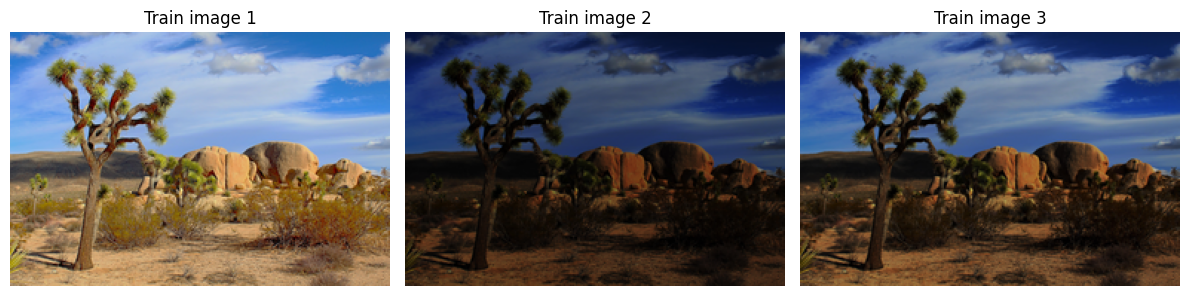

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(train_images[i])
    plt.title(f"Train image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

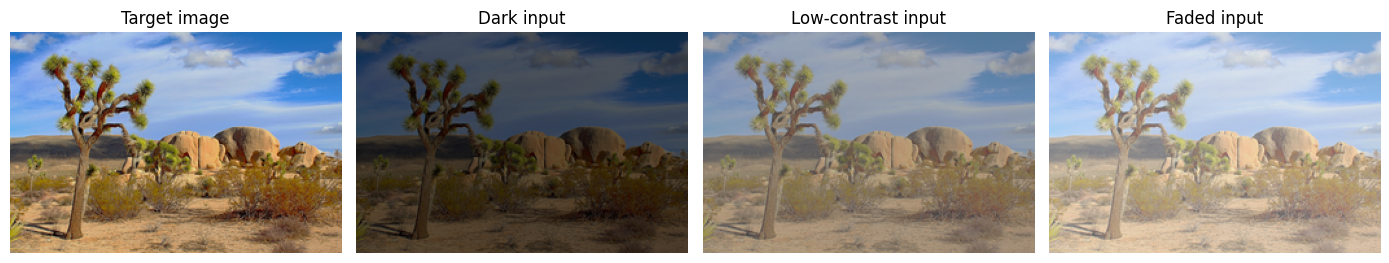

In [15]:
import numpy as np

def make_dark(image, factor=0.4):
    return np.clip(image.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def make_low_contrast(image, factor=0.5):
    image = image.astype(np.float32)
    mean = image.mean(axis=(0, 1), keepdims=True)
    return np.clip((image - mean) * factor + mean, 0, 255).astype(np.uint8)

def make_faded(image, strength=0.4):
    image = image.astype(np.float32)
    return np.clip(image * (1 - strength) + 255 * strength, 0, 255).astype(np.uint8)

# በመጀመሪያ አንድ reference ምስል እንፈትሽ
target_image = train_images[0]

dark_image = make_dark(target_image)
low_contrast_image = make_low_contrast(target_image)
faded_image = make_faded(target_image)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

images_to_show = [
    (target_image, "Target image"),
    (dark_image, "Dark input"),
    (low_contrast_image, "Low-contrast input"),
    (faded_image, "Faded input")
]

for i, (img, title) in enumerate(images_to_show):
    plt.subplot(1, 4, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Create input and target pairs for CNN training

train_inputs = []
train_targets = []

for image in train_images:
    # Dark image
    train_inputs.append(make_dark(image))
    train_targets.append(image)

    # Low-contrast image
    train_inputs.append(make_low_contrast(image))
    train_targets.append(image)

    # Faded image
    train_inputs.append(make_faded(image))
    train_targets.append(image)

train_inputs = np.array(train_inputs, dtype=np.uint8)
train_targets = np.array(train_targets, dtype=np.uint8)

print("Training data preparation completed!")
print("Training inputs:", train_inputs.shape)
print("Training targets:", train_targets.shape)

Training data preparation completed!
Training inputs: (3840, 171, 256, 3)
Training targets: (3840, 171, 256, 3)


In [17]:
# Prepare test input and target pairs

test_inputs = []
test_targets = []

for image in test_images:
    test_inputs.append(make_dark(image))
    test_targets.append(image)

    test_inputs.append(make_low_contrast(image))
    test_targets.append(image)

    test_inputs.append(make_faded(image))
    test_targets.append(image)

test_inputs = np.array(test_inputs, dtype=np.uint8)
test_targets = np.array(test_targets, dtype=np.uint8)

print("Test data preparation completed!")
print("Test inputs:", test_inputs.shape)
print("Test targets:", test_targets.shape)

Test data preparation completed!
Test inputs: (669, 171, 256, 3)
Test targets: (669, 171, 256, 3)


In [18]:
# Normalize pixel values from 0-255 to 0-1

train_inputs_norm = train_inputs.astype("float32") / 255.0
train_targets_norm = train_targets.astype("float32") / 255.0

test_inputs_norm = test_inputs.astype("float32") / 255.0
test_targets_norm = test_targets.astype("float32") / 255.0

print("Data normalization completed!")
print("Training input range:",
      train_inputs_norm.min(), "to", train_inputs_norm.max())
print("Training target range:",
      train_targets_norm.min(), "to", train_targets_norm.max())
print("Test input range:",
      test_inputs_norm.min(), "to", test_inputs_norm.max())
print("Test target range:",
      test_targets_norm.min(), "to", test_targets_norm.max())

Data normalization completed!
Training input range: 0.0 to 1.0
Training target range: 0.0 to 1.0
Test input range: 0.0 to 1.0
Test target range: 0.0 to 1.0


In [20]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# ==========================================
# IMAGE ENHANCEMENT MODEL
# Custom Multi-Branch CNN Architecture
# ==========================================

def create_image_enhancement_model():

    # Input image: height, width, RGB channels
    inputs = layers.Input(shape=(171, 256, 3), name="input_image")

    # Initial feature extraction
    initial = layers.Conv2D(
        32, 3, padding="same", activation="relu",
        name="initial_feature_extraction"
    )(inputs)

    # Branch 1: Brightness-related features
    brightness = layers.Conv2D(
        16, 3, padding="same", activation="relu",
        name="brightness_features"
    )(initial)

    brightness = layers.Conv2D(
        16, 3, padding="same", activation="relu",
        name="brightness_refinement"
    )(brightness)

    # Branch 2: Contrast-related features
    contrast = layers.Conv2D(
        16, 5, padding="same", activation="relu",
        name="contrast_features"
    )(initial)

    contrast = layers.Conv2D(
        16, 3, padding="same", activation="relu",
        name="contrast_refinement"
    )(contrast)

    # Branch 3: Image-detail features
    details = layers.Conv2D(
        16, 3, padding="same", activation="relu",
        name="detail_features"
    )(initial)

    details = layers.Conv2D(
        16, 1, padding="same", activation="relu",
        name="detail_refinement"
    )(details)

    # Combine features from all three branches
    combined = layers.Concatenate(
        name="feature_fusion"
    )([brightness, contrast, details, initial])

    # Learn how to reconstruct the enhanced image
    fused = layers.Conv2D(
        32, 3, padding="same", activation="relu",
        name="fusion_learning"
    )(combined)

    # Predict an image correction
    correction = layers.Conv2D(
        3, 3, padding="same", activation="tanh",
        name="image_correction"
    )(fused)

    # Add the correction to the original input
    corrected = layers.Add(
        name="residual_enhancement"
    )([inputs, correction])

    # Keep output pixels in the range 0 to 1
    outputs = layers.Activation(
        "sigmoid", name="enhanced_image"
    )(corrected)

    # Create the complete model
    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="Image_Enhancement_Model"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mean_squared_error",
        metrics=["mae"]
    )

    return model


# Create the new model
model = create_image_enhancement_model()

# Display the model structure
model.summary()


Model: "Image_Enhancement_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 171, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_feature_ex… │ (None, 171, 256,  │        896 │ input_image[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ brightness_features │ (None, 171, 256,  │      4,624 │ initial_feature_… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ contrast_features   │ (None, 171, 256,  │     12,816 │ initial_feature_… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ detail_features     │ (None, 171, 256,  │      4,624 │ initial_feature_… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ brightness_refinem… │ (None, 171, 256,  │      2,320 │ brightness_featu… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ contrast_refinement │ (None, 171, 256,  │      2,320 │ contrast_feature… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ detail_refinement   │ (None, 171, 256,  │        272 │ detail_features[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 171, 256,  │          0 │ brightness_refin… │
│ (Concatenate)       │ 80)               │            │ contrast_refinem… │
│                     │                   │            │ detail_refinemen… │
│                     │                   │            │ initial_feature_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_learning     │ (None, 171, 256,  │     23,072 │ feature_fusion[0… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_correction    │ (None, 171, 256,  │        867 │ fusion_learning[… │
│ (Conv2D)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_enhanceme… │ (None, 171, 256,  │          0 │ input_image[0][0… │
│ (Add)               │ 3)                │            │ image_correction… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enhanced_image      │ (None, 171, 256,  │          0 │ residual_enhance… │
│ (Activation)        │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 51,811 (202.39 KB)

 Trainable params: 51,811 (202.39 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:

import tensorflow as tf

# Prepare training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_inputs, train_targets)
)

train_dataset = train_dataset.map(
    lambda x, y: (
        tf.cast(x, tf.float32) / 255.0,
        tf.cast(y, tf.float32) / 255.0
    ),
    num_parallel_calls=1
).batch(4).prefetch(1)

# Prepare testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_inputs, test_targets)
)

test_dataset = test_dataset.map(
    lambda x, y: (
        tf.cast(x, tf.float32) / 255.0,
        tf.cast(y, tf.float32) / 255.0
    ),
    num_parallel_calls=1
).batch(4).prefetch(1)

print("Training and testing datasets are ready!")


Training and testing datasets are ready!
